# LegumAmies - ClimateShield climate pipeline (Milestone 1)

Reproducible agricultural decision pipeline for French legume growers.

**Data honesty legend**
- **Real weather forecast**: AROME France HD and ECMWF AIFS ensemble, fetched live.
- **User-provided farm information**: the demo field and machinery CSVs (hypothetical).
- **Agronomic evidence**: published thresholds (Terres Inovia) with sources.
- **Hypothetical scenario**: clearly labelled what-if demonstrations.

This notebook calls functions defined in `src/`; it contains orchestration only.
It runs in Kiro's Ubuntu environment, Google Colab and AWS Jupyter via
repository-relative paths.

In [1]:
# --- Environment bootstrap: locate repo root and import src -----------------
import sys, subprocess
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'src').is_dir() and (p / 'requirements.txt').exists():
            return p
    return start

try:
    HERE = Path(__file__).resolve().parent  # script execution
except NameError:
    HERE = Path.cwd()                        # interactive notebook

REPO_ROOT = find_repo_root(HERE)

# Google Colab convenience: clone the repo if src/ is not reachable.
if not (REPO_ROOT / 'src').is_dir():
    if 'google.colab' in sys.modules:
        subprocess.run(['git', 'clone', 'https://github.com/Eric-Kambire/LegumAmies'], check=False)
        REPO_ROOT = Path('LegumAmies').resolve()

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print('Repo root:', REPO_ROOT)

Repo root: /home/ubuntu/Downloads/LegumAmies


In [2]:
# Imports from the pipeline package
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.weather import arome, aifs, ensemble_processing
from src.risk import rules
from src.harvest import ranking
from src import pipeline

config.ensure_dirs()
print('Supported crops :', config.SUPPORTED_CROPS)
print('Growth stages   :', config.GROWTH_STAGES)

Supported crops : ('fava_bean', 'pea', 'chickpea', 'soybean', 'lentil', 'lupin', 'dry_bean')
Growth stages   : ('vegetative', 'flowering', 'pod_formation', 'grain_filling', 'harvest_ready')


## 1. Load field configuration (user-provided, hypothetical)

In [3]:
fields = config.load_fields()
display(fields)
field = config.get_field('DEMO_001')
field

,field_id,latitude,longitude,crop,growth_stage,area_ha,harvest_ready
0,DEMO_001,48.7,2.2,fava_bean,flowering,5,False


{'field_id': 'DEMO_001',
 'latitude': 48.7,
 'longitude': 2.2,
 'crop': 'fava_bean',
 'growth_stage': 'flowering',
 'area_ha': 5,
 'harvest_ready': False}

## 2. Retrieve AROME France HD forecast (real, short-term)

In [4]:
weather_df, arome_meta = arome.run(field, forecast_days=2, save=True)
print('Model   :', arome_meta['model_id'])
print('URL     :', arome_meta['url'])
print('Rows    :', arome_meta['n_rows'])
print('Vars ok :', arome_meta['available_variables'])
print('Missing :', arome_meta['missing_variables'])
print('Window  :', arome_meta['valid_time_local_start'], '->', arome_meta['valid_time_local_end'])

Model   : meteofrance_arome_france_hd
URL     : https://api.open-meteo.com/v1/meteofrance
Rows    : 48
Vars ok : ['temperature_2m', 'precipitation', 'relative_humidity_2m', 'wind_speed_10m']
Missing : []
Window  : 2026-10-31 00:00:00+01:00 -> 2026-11-01 23:00:00+01:00


## 3. Retrieve ECMWF AIFS ensemble forecast (real, uncertainty)

In [5]:
ensemble_df, aifs_meta = aifs.run(field, forecast_days=10, save=True)
print('Model        :', aifs_meta['model_id'])
print('URL          :', aifs_meta['url'])
print('Valid members:', aifs_meta['ensemble_members_valid'], '(expected max', aifs_meta['ensemble_members_expected_max'], ')')
print('Long rows    :', aifs_meta['n_rows_long'])
print('Window       :', aifs_meta['valid_time_local_start'], '->', aifs_meta['valid_time_local_end'])

Model        : ecmwf_aifs025_ensemble
URL          : https://ensemble-api.open-meteo.com/v1/ensemble
Valid members: 51 (expected max 51 )
Long rows    : 12240
Window       : 2026-10-31 00:00:00+01:00 -> 2026-11-09 23:00:00+01:00


## 4. Raw dataset structure

In [6]:
print('AROME hourly (head):')
display(weather_df.head())
print('AIFS ensemble long-format (head):')
display(ensemble_df.head())
print('Distinct ensemble members:', sorted(ensemble_df['member_id'].unique())[:5], '...')

AROME hourly (head):


,field_id,valid_time_utc,valid_time_local,temperature_c,precipitation_mm,relative_humidity_pct,wind_speed_kmh,model_id,retrieved_at_utc
0,DEMO_001,2026-10-30 23:00:00+00:00,2026-10-31 00:00:00+01:00,9.1,0.0,80,9.8,meteofrance_arome_france_hd,2026-10-31T16:09:51.213885+00:00
1,DEMO_001,2026-10-31 00:00:00+00:00,2026-10-31 01:00:00+01:00,8.5,0.0,84,9.0,meteofrance_arome_france_hd,2026-10-31T16:09:51.213885+00:00
2,DEMO_001,2026-10-31 01:00:00+00:00,2026-10-31 02:00:00+01:00,8.0,0.0,85,11.8,meteofrance_arome_france_hd,2026-10-31T16:09:51.213885+00:00
3,DEMO_001,2026-10-31 02:00:00+00:00,2026-10-31 03:00:00+01:00,7.6,0.0,86,10.3,meteofrance_arome_france_hd,2026-10-31T16:09:51.213885+00:00
4,DEMO_001,2026-10-31 03:00:00+00:00,2026-10-31 04:00:00+01:00,7.0,0.0,88,7.9,meteofrance_arome_france_hd,2026-10-31T16:09:51.213885+00:00


AIFS ensemble long-format (head):


,field_id,valid_time_utc,valid_time_local,member_id,precipitation_mm,model_id
0,DEMO_001,2026-10-30 23:00:00+00:00,2026-10-31 00:00:00+01:00,member00,0.0,ecmwf_aifs025_ensemble
1,DEMO_001,2026-10-31 00:00:00+00:00,2026-10-31 01:00:00+01:00,member00,0.0,ecmwf_aifs025_ensemble
2,DEMO_001,2026-10-31 01:00:00+00:00,2026-10-31 02:00:00+01:00,member00,0.0,ecmwf_aifs025_ensemble
3,DEMO_001,2026-10-31 02:00:00+00:00,2026-10-31 03:00:00+01:00,member00,0.0,ecmwf_aifs025_ensemble
4,DEMO_001,2026-10-31 03:00:00+00:00,2026-10-31 04:00:00+01:00,member00,0.0,ecmwf_aifs025_ensemble


Distinct ensemble members: ['member00', 'member01', 'member02', 'member03', 'member04'] ...


## 5. Clean and validate

In [7]:
# Basic validation: no gaps in the AROME hourly index, numeric ranges sane.
assert weather_df['valid_time_utc'].is_monotonic_increasing, 'AROME times not sorted'
assert weather_df['temperature_c'].notna().all(), 'missing temperature values'
n_members = ensemble_df['member_id'].nunique()
assert n_members >= 1, 'no ensemble members parsed'
assert (ensemble_df['precipitation_mm'] >= 0).all(), 'negative precipitation'
print(f'Validation OK: {len(weather_df)} AROME rows, {n_members} ensemble members, '
      f'{len(ensemble_df)} ensemble rows')

Validation OK: 48 AROME rows, 51 ensemble members, 12240 ensemble rows


## 6. Temperature and precipitation charts (AROME)

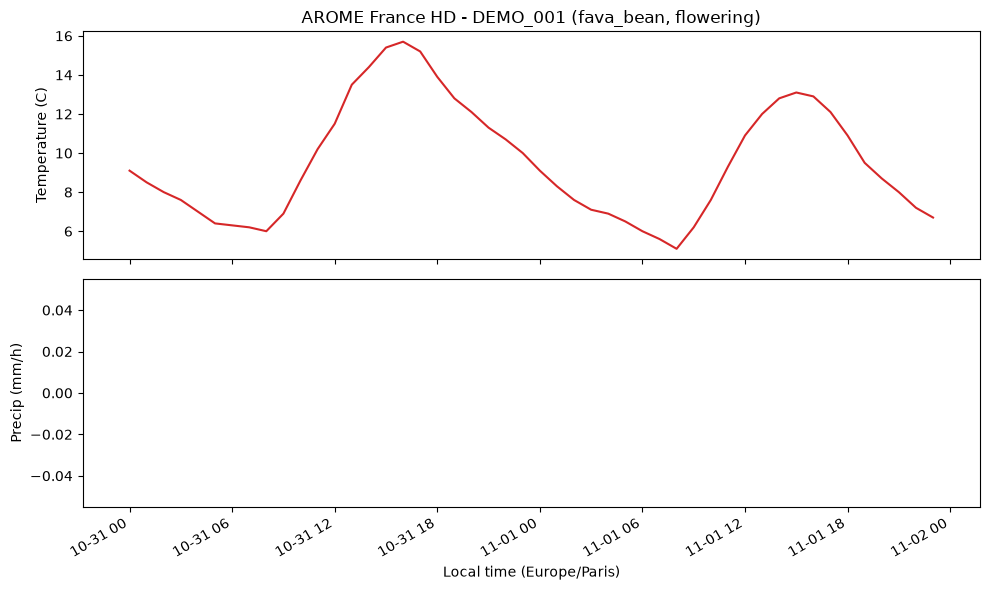

In [8]:
t = pd.to_datetime(weather_df['valid_time_local'])
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(t, weather_df['temperature_c'], color='tab:red')
ax[0].set_ylabel('Temperature (C)')
ax[0].set_title(f"AROME France HD - {field['field_id']} ({field['crop']}, {field['growth_stage']})")
ax[1].bar(t, weather_df['precipitation_mm'], width=0.03, color='tab:blue')
ax[1].set_ylabel('Precip (mm/h)')
ax[1].set_xlabel('Local time (Europe/Paris)')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 7. Rainfall probabilities from individual ensemble members
`P(rain > 5 mm / 24 h) = members exceeding / valid members`. The 5 mm threshold is an operational **demo** value, not a validated harvest limit.

,field_id,date_local,rain_threshold_mm,probability_pct,ensemble_members_used,mean_precipitation_mm,median_precipitation_mm,model_id
0,DEMO_001,2026-10-31,5.0,0.0,51,0.000,0.0,ecmwf_aifs025_ensemble
1,DEMO_001,2026-11-01,5.0,0.0,51,0.000,0.0,ecmwf_aifs025_ensemble
2,DEMO_001,2026-11-02,5.0,0.0,51,0.412,0.0,ecmwf_aifs025_ensemble
3,DEMO_001,2026-11-03,5.0,0.0,51,0.294,0.0,ecmwf_aifs025_ensemble
4,DEMO_001,2026-11-04,5.0,0.0,51,0.192,0.0,ecmwf_aifs025_ensemble
5,DEMO_001,2026-11-05,5.0,0.0,51,0.325,0.0,ecmwf_aifs025_ensemble
6,DEMO_001,2026-11-06,5.0,3.9,51,1.153,0.0,ecmwf_aifs025_ensemble
7,DEMO_001,2026-11-07,5.0,3.9,51,0.855,0.0,ecmwf_aifs025_ensemble
8,DEMO_001,2026-11-08,5.0,3.9,51,1.114,0.0,ecmwf_aifs025_ensemble
9,DEMO_001,2026-11-09,5.0,5.9,51,1.192,0.2,ecmwf_aifs025_ensemble


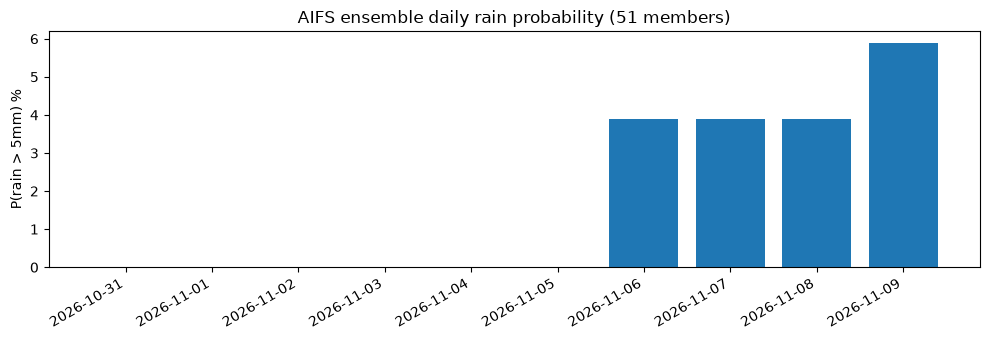

In [9]:
prob_df, prob_meta = ensemble_processing.run(ensemble_df, threshold_mm=config.DEFAULT_RAIN_THRESHOLD_MM, save=True)
display(prob_df)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(prob_df['date_local'], prob_df['probability_pct'], color='tab:blue')
ax.set_ylabel('P(rain > 5mm) %')
ax.set_title(f"AIFS ensemble daily rain probability ({prob_meta['members_used_max']} members)")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 8. Evaluate crop-stage weather risk conditions
Only **published**, sourced thresholds are active. An empty table is a valid, honest result (no hazard condition met in the forecast window).

In [10]:
alerts_df, risk_meta = rules.run(weather_df, field, save=True)
print('Active published rules for this crop/stage:', risk_meta['active_published_rules_for_stage'])
print('Alerts raised:', risk_meta['n_alerts'])
print('Note:', risk_meta['note'])
display(alerts_df if len(alerts_df) else 'No hazard thresholds exceeded in the forecast window.')
print('\nAgronomic rules in catalogue (with provenance):')
display(config.load_crop_rules())

Active published rules for this crop/stage: 1
Alerts raised: 0
Note: Threshold exceedance is a risk flag, not a prediction of crop damage.


'No hazard thresholds exceeded in the forecast window.'


Agronomic rules in catalogue (with provenance):


,crop,growth_stage,hazard_type,weather_variable,threshold_value,comparison_operator,minimum_exposure_hours,source_url,validation_status
0,fava_bean,flowering,heat_stress,temperature_2m,25,gt,1,https://www.terresinovia.fr/fr/informations-te...,published
1,fava_bean,grain_filling,heat_stress,temperature_2m,25,gt,1,https://www.terresinovia.fr/fr/informations-te...,published
2,fava_bean,vegetative,frost,temperature_2m,-12,lt,1,https://www.terresinovia.fr/fr/informations-te...,published
3,pea,flowering,heat_stress,temperature_2m,25,gt,1,https://www.terresinovia.fr/fr/informations-te...,published
4,fava_bean,flowering,excess_rain,precipitation,20,gt,24,,requires_expert_validation
5,fava_bean,harvest_ready,wet_harvest,precipitation,5,gt,24,,demo_hypothetical


## 9. Rank available harvest windows
The demo field is **not** harvest-ready, so no date is recommended (the readiness guard is working). Below we also show a clearly-labelled **hypothetical** where the field is harvest-ready, to exercise the ranker.

In [11]:
ranking_df, harvest_meta = ranking.run(field, prob_df, save=True)
print('Feasible days (real field, harvest_ready=%s):' % field['harvest_ready'], harvest_meta['n_feasible_days'])
display(ranking_df)

Feasible days (real field, harvest_ready=False): 0


,field_id,date_local,feasible,rain_probability_pct,expected_rain_mm,weather_risk_score,rank,explanation,limitations
0,DEMO_001,2026-10-31,False,0.0,0.000,0.00,<NA>,crop not declared harvest-ready,"weather-only, provisional (no grain-moisture /..."
1,DEMO_001,2026-11-01,False,0.0,0.000,0.00,<NA>,crop not declared harvest-ready; harvesting ma...,"weather-only, provisional (no grain-moisture /..."
2,DEMO_001,2026-11-02,False,0.0,0.412,0.62,<NA>,crop not declared harvest-ready,"weather-only, provisional (no grain-moisture /..."
3,DEMO_001,2026-11-03,False,0.0,0.294,0.44,<NA>,crop not declared harvest-ready,"weather-only, provisional (no grain-moisture /..."
4,DEMO_001,2026-11-04,False,0.0,0.192,0.29,<NA>,crop not declared harvest-ready; harvesting ma...,"weather-only, provisional (no grain-moisture /..."
5,DEMO_001,2026-11-05,False,0.0,0.325,0.49,<NA>,crop not declared harvest-ready,"weather-only, provisional (no grain-moisture /..."
6,DEMO_001,2026-11-06,False,3.9,1.153,4.46,<NA>,crop not declared harvest-ready,"weather-only, provisional (no grain-moisture /..."
7,DEMO_001,2026-11-07,False,3.9,0.855,4.01,<NA>,crop not declared harvest-ready,"weather-only, provisional (no grain-moisture /..."
8,DEMO_001,2026-11-08,False,3.9,1.114,4.40,<NA>,crop not declared harvest-ready; harvesting ma...,"weather-only, provisional (no grain-moisture /..."
9,DEMO_001,2026-11-09,False,5.9,1.192,5.92,<NA>,crop not declared harvest-ready,"weather-only, provisional (no grain-moisture /..."


In [12]:
# HYPOTHETICAL what-if: pretend the crop is harvest-ready (not a real claim).
hypo_df, hypo_meta = ranking.run(field, prob_df, harvest_ready_override=True, save=False)
print('HYPOTHETICAL harvest-ready scenario')
print('Recommended date:', hypo_meta['recommended_date_local'], '| weights:', hypo_meta['weights'])
display(hypo_df[hypo_df['feasible']].sort_values('rank'))

HYPOTHETICAL harvest-ready scenario
Recommended date: 2026-10-31 | weights: {'rain_probability': 0.7, 'rain_amount': 0.3, 'reference_rain_mm': 20.0}


,field_id,date_local,feasible,rain_probability_pct,expected_rain_mm,weather_risk_score,rank,explanation,limitations
0,DEMO_001,2026-10-31,True,0.0,0.000,0.00,1,"feasible: 0% ensemble rain-prob >5mm, expected...","weather-only, provisional (no grain-moisture /..."
3,DEMO_001,2026-11-03,True,0.0,0.294,0.44,2,"feasible: 0% ensemble rain-prob >5mm, expected...","weather-only, provisional (no grain-moisture /..."
5,DEMO_001,2026-11-05,True,0.0,0.325,0.49,3,"feasible: 0% ensemble rain-prob >5mm, expected...","weather-only, provisional (no grain-moisture /..."
2,DEMO_001,2026-11-02,True,0.0,0.412,0.62,4,"feasible: 0% ensemble rain-prob >5mm, expected...","weather-only, provisional (no grain-moisture /..."
7,DEMO_001,2026-11-07,True,3.9,0.855,4.01,5,"feasible: 4% ensemble rain-prob >5mm, expected...","weather-only, provisional (no grain-moisture /..."
6,DEMO_001,2026-11-06,True,3.9,1.153,4.46,6,"feasible: 4% ensemble rain-prob >5mm, expected...","weather-only, provisional (no grain-moisture /..."
9,DEMO_001,2026-11-09,True,5.9,1.192,5.92,7,"feasible: 6% ensemble rain-prob >5mm, expected...","weather-only, provisional (no grain-moisture /..."


## 10. Export all processed datasets + run metadata

In [13]:
pipeline.write_run_metadata(field, arome_meta, aifs_meta, prob_meta, risk_meta, harvest_meta)
import os
for f in sorted(os.listdir(config.PROCESSED_DIR)):
    print(' -', (config.PROCESSED_DIR / f).relative_to(config.ROOT))

 - data/processed/.gitkeep
 - data/processed/ensemble_hourly.csv
 - data/processed/flowering_alerts.csv
 - data/processed/harvest_ranking.csv
 - data/processed/rain_probabilities.csv
 - data/processed/run_metadata.json
 - data/processed/weather_hourly.csv


## 11. Execution summary

In [14]:
print('ClimateShield Milestone 1 - execution summary')
print('=' * 52)
print(f"Field              : {field['field_id']} ({field['crop']}, {field['growth_stage']})")
print(f"Coordinates        : {field['latitude']}, {field['longitude']}")
print(f"AROME model        : {arome_meta['model_id']}")
print(f"AROME rows         : {arome_meta['n_rows']} | vars: {arome_meta['available_variables']}")
print(f"AROME window       : {arome_meta['valid_time_local_start']} -> {arome_meta['valid_time_local_end']}")
print(f"AIFS model         : {aifs_meta['model_id']}")
print(f"AIFS members       : {aifs_meta['ensemble_members_valid']} | long rows: {aifs_meta['n_rows_long']}")
print(f"AIFS window        : {aifs_meta['valid_time_local_start']} -> {aifs_meta['valid_time_local_end']}")
print(f"Rain-prob days     : {prob_meta['n_days']} (threshold {prob_meta['rain_threshold_mm']} mm)")
print(f"Risk alerts        : {risk_meta['n_alerts']} (active rules: {risk_meta['active_published_rules_for_stage']})")
print(f"Harvest feasible   : {harvest_meta['n_feasible_days']} | recommended: {harvest_meta['recommended_date_local']}")
print('Done.')

ClimateShield Milestone 1 - execution summary
Field              : DEMO_001 (fava_bean, flowering)
Coordinates        : 48.7, 2.2
AROME model        : meteofrance_arome_france_hd
AROME rows         : 48 | vars: ['temperature_2m', 'precipitation', 'relative_humidity_2m', 'wind_speed_10m']
AROME window       : 2026-10-31 00:00:00+01:00 -> 2026-11-01 23:00:00+01:00
AIFS model         : ecmwf_aifs025_ensemble
AIFS members       : 51 | long rows: 12240
AIFS window        : 2026-10-31 00:00:00+01:00 -> 2026-11-09 23:00:00+01:00
Rain-prob days     : 10 (threshold 5.0 mm)
Risk alerts        : 0 (active rules: 1)
Harvest feasible   : 0 | recommended: None
Done.
